In [1]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar

/home/links/mf671/miniconda3/envs/falwa_env/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [4]:
ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

# Load datasets
ds_clims = []
compute_climatology = False
if compute_climatology:
    for experiment in experiments:
        print(experiment)
        print(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc')
        tke = flip_and_append(xr.open_mfdataset(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc',
                                                parallel=True,
                                                chunks={'time': 30}))['tke'].loc[:,250,:,:].mean('time')
        tke_std = (flip_and_append(xr.open_mfdataset(f'{base_path}/{experiment}/tot/TKE_monthly_2.5x2.5_2-51.nc',
                                                parallel=True,
                                                chunks={'time': 30}))['tke'].loc[:,250,:,:].std('time')/np.sqrt(2*12*50)).rename('tke_std')
        dw_lwa = xr.open_mfdataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['dw_lwa'].mean('time')
        dw_lwa_std = (xr.open_mfdataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc',
                                parallel=True,
                                chunks={'time': 30})['dw_lwa'].std('time')/np.sqrt(2*365*50)).rename('dw_lwa_std')
        print(tke_std.shape,tke.shape,dw_lwa_std.shape,dw_lwa.shape)
        ds = xr.merge([tke,dw_lwa,tke_std,dw_lwa_std])
        ds.to_netcdf(f'{base_path}/{experiment}/TKE_dw_lwa_CLIM_1.5x1.5.nc')
        ds_clims.append(ds)
else:
    for experiment in experiments:
        ds = xr.open_dataset(f'{base_path}/{experiment}/TKE_dw_lwa_CLIM_1.5x1.5.nc')
        ds_clims.append(ds)

# Load blocking data
DA_clims = []

for experiment in tqdm(experiments):
    ds = xr.open_dataset(f'{base_path}/{experiment}/tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc')
    DA_clims.append((xr.where(ds['LWAA_tracked']>0,1,0).mean('time'))*100)
    ds.close()

exeter_project_mf_baseline_KS
/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/tot/TKE_monthly_2.5x2.5_2-51.nc
[########################################] | 100% Completed | 8.13 ss
[########################################] | 100% Completed | 8.23 s
[########################################] | 100% Completed | 102.57 ms
[########################################] | 100% Completed | 201.43 ms
[########################################] | 100% Completed | 519.99 ms
[########################################] | 100% Completed | 619.68 ms
[########################################] | 100% Completed | 102.79 ms
[########################################] | 100% Completed | 201.38 ms
(61, 240) (61, 240) (61, 240) (61, 240)
[#################                       ] | 42% Completed | 43.04 ss
[#################                       ] | 42% Completed | 43.04 s

KeyboardInterrupt: 

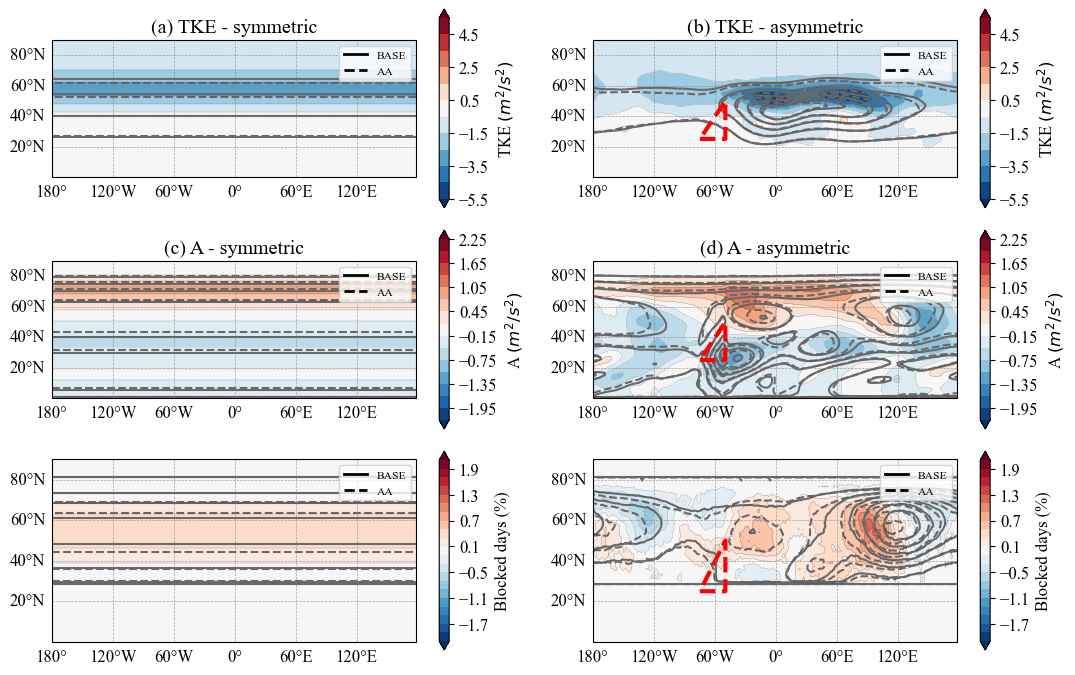

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.lines import Line2D  # <-- Add this import at the top of your cell

# Set global font family and size
plt.rcParams['font.family'] = 'Times New Roman'      # e.g., 'serif', 'sans-serif', 'monospace'
plt.rcParams['font.size'] = 12             # default font size

fig, ax = plt.subplots(3, 2, figsize=(11, 7), subplot_kw={'projection': ccrs.PlateCarree()})
ax = ax.T.flatten()  # transpose then flatten: ordering = [col0_row1, col0_row2, col0_row3, col1_row1, col1_row2, col1_row3]

titles = ['symmetric', 'asymmetric']
letters = ['(a)','(c)','(c)','(b)','(d)','(f)']

coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

for i in range(2):
    base = i * 3
    ax_tke = ax[base + 0]    # row 1 of column i
    ax_lwa = ax[base + 1]    # row 2 of column i
    ax_block = ax[base + 2]  # row 3 of column i (this places blocking in the last row)
    if i == 0:
        ds_a = ds_clims[i * 2].mean('lon').broadcast_like(ds_clims[i*2]).transpose()     # baseline
        ds_b = ds_clims[i * 2 + 1].mean('lon').broadcast_like(ds_clims[i*2]).transpose()  # AA
        da_a_block = DA_clims[i * 2].mean('lon').broadcast_like(ds_clims[i*2]).transpose()  
        da_b_block = DA_clims[i * 2 + 1].mean('lon').broadcast_like(ds_clims[i*2]).transpose() 
    if i == 1:
        ds_a = ds_clims[i * 2]     # baseline
        ds_b = ds_clims[i * 2 + 1] # AA
        da_a_block = DA_clims[i * 2] 
        da_b_block = DA_clims[i * 2 + 1]
        

    # TKE
    levels_tke = np.linspace(0, 100, 10)
    levels_tke_diff = np.arange(-5.5, 6, 1)
    ax_tke.set_title(f'{letters[i*3+0]} TKE - {titles[i]}')
    cont = ax_tke.contour(ds_a['lon'], ds_a['lat'], ds_a['tke'], levels=levels_tke, colors='dimgray', linestyles = 'solid', linewidths = 1.5, transform=ccrs.PlateCarree())
    ax_tke.contour(ds_b['lon'], ds_b['lat'], ds_b['tke'], levels=levels_tke, colors='dimgray', linestyles = 'dashed', linewidths = 1.5, transform=ccrs.PlateCarree())
    sh = ax_tke.contourf(ds_a['lon'], ds_a['lat'], ds_b['tke'] - ds_a['tke'],
                         levels=levels_tke_diff, cmap='RdBu_r', extend='both', transform=ccrs.PlateCarree())
    ax_tke.contour(ds_a['lon'], ds_a['lat'], ds_b['tke'] - ds_a['tke'],
                    levels=levels_tke_diff, colors = 'k' , negative_linestyles = 'solid', linewidths = 0.1, transform=ccrs.PlateCarree())    
    ax_tke.set_aspect(1.5)
#    ax_tke.clabel(cont,colors='k')
    fig.colorbar(sh, ax=ax_tke, orientation='vertical', label='TKE $(m^2/s^2)$')
    if i > 0:
        ax_tke.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    gl0 = ax_tke.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl0.top_labels = False
    gl0.right_labels = False
    custom_lines = [
        Line2D([0], [0], color='black', lw=2, linestyle='solid', label='BASE'),
        Line2D([0], [0], color='black', lw=2, linestyle='dashed', label='AA')
    ]
    ax_tke.legend(handles=custom_lines, loc='upper right',fontsize='x-small')

    # dw_lwa
    levels_lwa = np.linspace(5, 25, 8)
    levels_lwa_diff = np.arange(-2.25, 2.3, 0.3)
    ax_lwa.set_title(f'{letters[i*3+1]} A - {titles[i]}')
    cont = ax_lwa.contour(ds_a['lon'], ds_a['lat'], ds_a['dw_lwa'], levels=levels_lwa, colors='dimgray', linestyles = 'solid', linewidths = 1.5, transform=ccrs.PlateCarree())
    ax_lwa.contour(ds_b['lon'], ds_b['lat'], ds_b['dw_lwa'], levels=levels_lwa, colors='dimgray', linestyles = 'dashed', linewidths = 1.5, transform=ccrs.PlateCarree())
    sh2 = ax_lwa.contourf(ds_a['lon'], ds_a['lat'], ds_b['dw_lwa'] - ds_a['dw_lwa'],
                          levels=levels_lwa_diff, cmap='RdBu_r', extend='both', transform=ccrs.PlateCarree())
    ax_lwa.contour(ds_a['lon'], ds_a['lat'], ds_b['dw_lwa'] - ds_a['dw_lwa'],
                    levels=levels_lwa_diff, colors = 'k' , negative_linestyles = 'solid', linewidths = 0.1, transform=ccrs.PlateCarree())    
    ax_lwa.set_aspect(1.5)
#    ax_lwa.clabel(cont,colors='k')
    fig.colorbar(sh2, ax=ax_lwa, orientation='vertical', label='A $(m^2/s^2)$')
    if i > 0:
        ax_lwa.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    gl1 = ax_lwa.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl1.top_labels = False
    gl1.right_labels = False
    custom_lines = [
        Line2D([0], [0], color='black', lw=2, linestyle='solid', label='BASE'),
        Line2D([0], [0], color='black', lw=2, linestyle='dashed', label='AA')
    ]
    ax_lwa.legend(handles=custom_lines, loc='upper right',fontsize='x-small')
    
    # Blocking frequency (placed on the third row of each column)
    levels_block = np.arange(0, 12, 1)    # percent
    levels_block_diff = np.arange(-2.1, 2.2, 0.2)
#    ax_block.set_title(f'{letters[i*3+2]} Blocking frequency - {titles[i]}')
    cont = ax_block.contour(ds_a['lon'], ds_a['lat'], da_a_block, levels=levels_block, colors='dimgray', linestyles = 'solid', linewidths = 1.5, transform=ccrs.PlateCarree())
    ax_block.contour(ds_b['lon'], ds_b['lat'], da_b_block, levels=levels_block, colors='dimgray', linestyles = 'dashed', linewidths = 1.5, transform=ccrs.PlateCarree())
    sh3 = ax_block.contourf(ds_a['lon'], ds_a['lat'], da_b_block - da_a_block,
                            levels=levels_block_diff, cmap='RdBu_r', extend='both', transform=ccrs.PlateCarree())
    ax_block.contour(ds_a['lon'], ds_a['lat'], da_b_block - da_a_block,
                     levels=levels_block_diff, colors = 'k' , negative_linestyles = 'solid', linewidths = 0.1, transform=ccrs.PlateCarree())    
    ax_block.set_aspect(2)
#    ax_block.clabel(cont,colors='k')
    fig.colorbar(sh3, ax=ax_block, orientation='vertical', label='Blocked days (%)')
    if i > 0:
        ax_block.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    glb = ax_block.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    glb.top_labels = False
    glb.right_labels = False
    custom_lines = [
        Line2D([0], [0], color='black', lw=2, linestyle='solid', label='BASE'),
        Line2D([0], [0], color='black', lw=2, linestyle='dashed', label='AA')
    ]
    ax_block.legend(handles=custom_lines, loc='upper right',fontsize='x-small')

plt.tight_layout()
plt.savefig('PLOTS/Figure5.png',dpi=300)